In [ ]:
import pandas as pd

df = pd.read_csv('/content/weight-height.csv')

df.head()

,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801


In [ ]:

print("Dataset Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
display(df.head())
print("\nMissing Values:\n", df.isnull().sum())


Dataset Shape: (10000, 3)

Columns: ['Gender', 'Height', 'Weight']


,Gender,Height,Weight
0,Male,73.847017,241.893563
1,Male,68.781904,162.310473
2,Male,74.110105,212.740856
3,Male,71.730978,220.042470
4,Male,69.881796,206.349801



Missing Values:
 Gender    0
Height    0
Weight    0
dtype: int64


In [ ]:

# Remove duplicate rows and missing values
df = df.drop_duplicates().dropna().copy()

# Standardize column names
df.columns = df.columns.str.strip()

# Convert measurements to standard units
df['Height_cm'] = df['Height'] * 2.54
df['Weight_kg'] = df['Weight'] * 0.45359237

# Keep only valid measurements
df = df[
    (df['Height_cm'] > 0) &
    (df['Weight_kg'] > 0)
].copy()

print("Cleaned dataset shape:", df.shape)
display(df[['Gender', 'Height_cm', 'Weight_kg']].head())


Cleaned dataset shape: (10000, 5)


,Gender,Height_cm,Weight_kg
0,Male,187.571423,109.721075
1,Male,174.706036,73.622792
2,Male,188.239668,96.497629
3,Male,182.196685,99.809586
4,Male,177.499761,93.598695


In [ ]:

# Install visualization libraries if needed
!pip install -q matplotlib seaborn plotly

# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Set a beautiful color palette
COLORS = {
    "teal": "#00BFA6",
    "blue": "#4361EE",
    "purple": "#845EC2",
    "coral": "#FF6B6B",
    "gold": "#FFC75F",
    "pink": "#F9A8D4",
    "background": "#F8FAFC",
    "text": "#243047"
}

PALETTE = [
    COLORS["teal"], COLORS["blue"], COLORS["purple"],
    COLORS["coral"], COLORS["gold"], COLORS["pink"]
]

# Global graph styling
sns.set_theme(style="whitegrid", context="notebook")
sns.set_palette(PALETTE)

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.facecolor"] = COLORS["background"]
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlesize"] = 15
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["axes.titlecolor"] = COLORS["text"]
plt.rcParams["axes.labelcolor"] = COLORS["text"]
plt.rcParams["xtick.color"] = COLORS["text"]
plt.rcParams["ytick.color"] = COLORS["text"]
plt.rcParams["grid.alpha"] = 0.25

print("Visualization libraries imported successfully!")


Visualization libraries imported successfully!


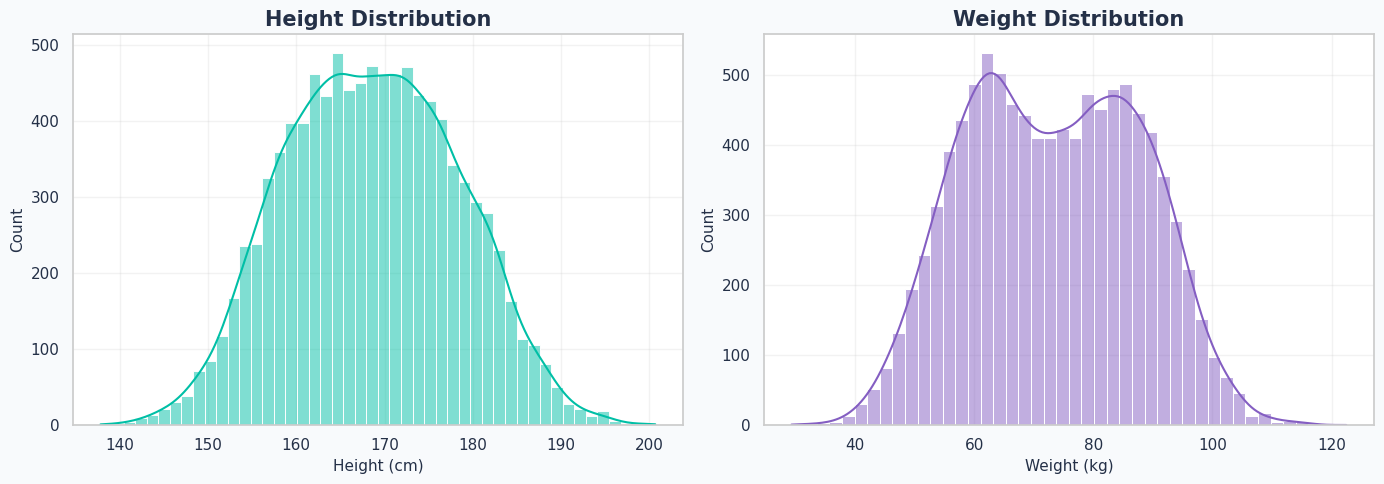

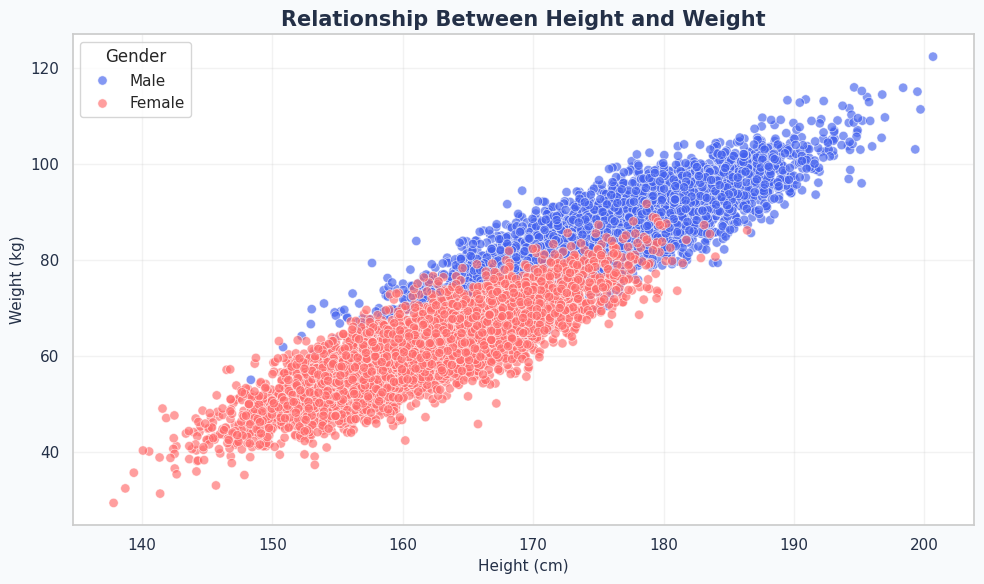

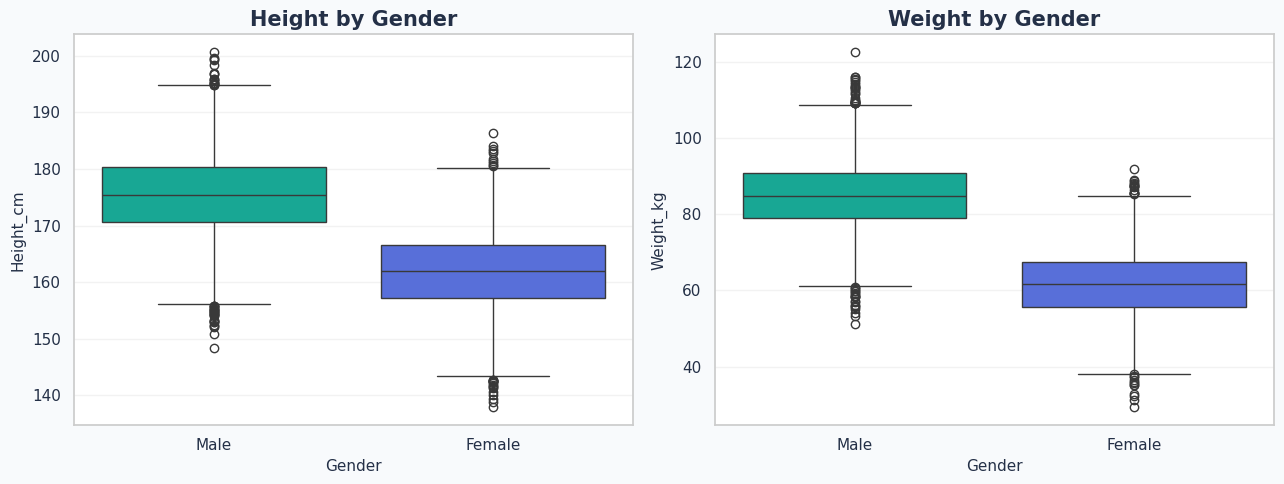

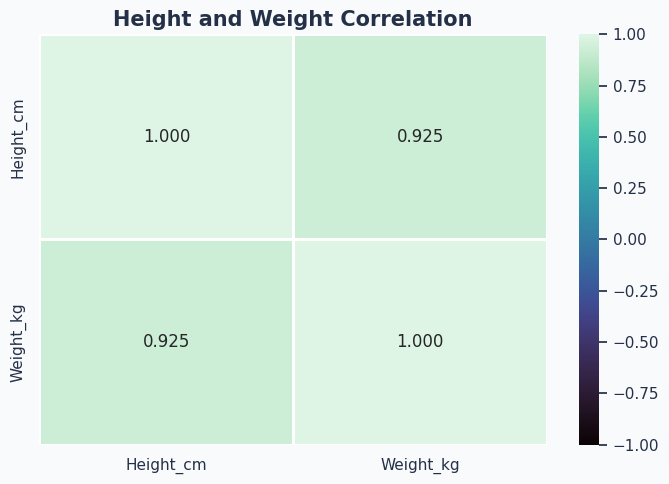

In [ ]:

# 1. Height and weight distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df, x="Height_cm", kde=True,
    color=COLORS["teal"], ax=axes[0]
)
axes[0].set_title("Height Distribution")
axes[0].set_xlabel("Height (cm)")

sns.histplot(
    data=df, x="Weight_kg", kde=True,
    color=COLORS["purple"], ax=axes[1]
)
axes[1].set_title("Weight Distribution")
axes[1].set_xlabel("Weight (kg)")

plt.tight_layout()
plt.show()

# 2. Height versus weight by gender
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="Height_cm",
    y="Weight_kg",
    hue="Gender",
    palette=[COLORS["blue"], COLORS["coral"]],
    alpha=0.65,
    s=45
)
plt.title("Relationship Between Height and Weight")
plt.xlabel("Height (cm)")
plt.ylabel("Weight (kg)")
plt.legend(title="Gender")
plt.tight_layout()
plt.show()

# 3. Gender-wise comparison
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(
    data=df, x="Gender", y="Height_cm",
    hue="Gender", palette=PALETTE[:2],
    legend=False, ax=axes[0]
)
axes[0].set_title("Height by Gender")

sns.boxplot(
    data=df, x="Gender", y="Weight_kg",
    hue="Gender", palette=PALETTE[:2],
    legend=False, ax=axes[1]
)
axes[1].set_title("Weight by Gender")

plt.tight_layout()
plt.show()

# 4. Correlation heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(
    df[["Height_cm", "Weight_kg"]].corr(),
    annot=True,
    cmap="mako",
    fmt=".3f",
    linewidths=1,
    vmin=-1,
    vmax=1
)
plt.title("Height and Weight Correlation")
plt.tight_layout()
plt.show()


In [10]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

# Define all nine regression models
models = {
    "Linear Regression": LinearRegression(),
    "Polynomial Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.01, max_iter=10000),
    "Decision Tree": DecisionTreeRegressor(
        random_state=42, max_depth=12
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=150, random_state=42, n_jobs=-1
    ),
    "SVR": SVR(kernel="rbf"),
    "KNN": KNeighborsRegressor(n_neighbors=5),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100, random_state=42
    )
}

# Evaluate models for both prediction targets
results = []
best_models = {}

tasks = [
    ("Weight Prediction", "Height_cm", "Weight_kg"),
    ("Height Prediction", "Weight_kg", "Height_cm")
]

for task_name, input_col, target_col in tasks:
    X = df[[input_col, "Gender"]]
    y = df[target_col]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42
    )

    for model_name, regressor in models.items():

        # Polynomial features apply only to the numeric input
        if model_name == "Polynomial Regression":
            numeric_transformer = Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("poly", PolynomialFeatures(
                    degree=2, include_bias=False
                )),
                ("scaler", StandardScaler())
            ])
        else:
            numeric_transformer = Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ])

        categorical_transformer = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ])

        preprocessor = ColumnTransformer([
            ("num", numeric_transformer, [input_col]),
            ("cat", categorical_transformer, ["Gender"])
        ])

        pipeline = Pipeline([
            ("preprocessor", preprocessor),
            ("regressor", regressor)
        ])

        # Fit on training data
        pipeline.fit(X_train, y_train)

        # Test-set predictions
        predictions = pipeline.predict(X_test)

        r2 = r2_score(y_test, predictions)
        mae = mean_absolute_error(y_test, predictions)
        rmse = np.sqrt(mean_squared_error(y_test, predictions))

        # Five-fold cross-validation RMSE
        cv_scores = cross_val_score(
            pipeline,
            X_train,
            y_train,
            cv=5,
            scoring="neg_root_mean_squared_error",
            n_jobs=-1
        )
        cv_rmse = -cv_scores.mean()

        results.append({
            "Task": task_name,
            "Model": model_name,
            "R2": r2,
            "MAE": mae,
            "RMSE": rmse,
            "CV_RMSE": cv_rmse
        })

        print(
            f"{task_name} | {model_name} | "
            f"R2={r2:.4f}, MAE={mae:.4f}, "
            f"RMSE={rmse:.4f}, CV RMSE={cv_rmse:.4f}"
        )

# Display comparison of all nine models
results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
display(
    results_df.sort_values(
        ["Task", "CV_RMSE", "RMSE"]
    ).round(4)
)

# Select the decided models for each task
for task_name, input_col, target_col in tasks:

    # Modified selection: Linear for Weight, Polynomial for Height
    best_name = (
        "Linear Regression"
        if task_name == "Weight Prediction"
        else "Polynomial Regression"
    )

    # Recreate the selected model with the same preprocessing
    regressor = models[best_name]

    if best_name == "Polynomial Regression":
        numeric_transformer = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("poly", PolynomialFeatures(
                degree=2, include_bias=False
            )),
            ("scaler", StandardScaler())
        ])
    else:
        numeric_transformer = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ])

    preprocessor = ColumnTransformer([
        ("num", numeric_transformer, [input_col]),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), ["Gender"])
    ])

    best_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", regressor)
    ])

    X = df[[input_col, "Gender"]]
    y = df[target_col]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42
    )

    best_pipeline.fit(X_train, y_train)

    # Store the selected model and its details
    best_models[task_name] = {
        "model": best_pipeline,
        "model_name": best_name,
        "input_col": input_col,
        "target_col": target_col
    }

    # Display metrics for the selected model
    predictions = best_pipeline.predict(X_test)

    print(f"\nSelected model for {task_name}: {best_name}")
    print(f"R2 Score: {r2_score(y_test, predictions):.4f}")
    print(f"MAE: {mean_absolute_error(y_test, predictions):.4f}")
    print(
        f"RMSE: "
        f"{np.sqrt(mean_squared_error(y_test, predictions)):.4f}"
    )

print("\nBoth selected models trained successfully!")

Weight Prediction | Linear Regression | R2=0.9033, MAE=3.6116, RMSE=4.5641, CV RMSE=4.5376
Weight Prediction | Polynomial Regression | R2=0.9033, MAE=3.6120, RMSE=4.5643, CV RMSE=4.5381
Weight Prediction | Ridge Regression | R2=0.9033, MAE=3.6116, RMSE=4.5641, CV RMSE=4.5376
Weight Prediction | Lasso Regression | R2=0.9033, MAE=3.6118, RMSE=4.5643, CV RMSE=4.5376
Weight Prediction | Decision Tree | R2=0.8737, MAE=4.0576, RMSE=5.2165, CV RMSE=5.3595
Weight Prediction | Random Forest | R2=0.8616, MAE=4.3095, RMSE=5.4616, CV RMSE=5.5265
Weight Prediction | SVR | R2=0.9029, MAE=3.6153, RMSE=4.5733, CV RMSE=4.5999
Weight Prediction | KNN | R2=0.8827, MAE=3.9828, RMSE=5.0277, CV RMSE=4.9884
Weight Prediction | Gradient Boosting | R2=0.9012, MAE=3.6533, RMSE=4.6150, CV RMSE=4.5725
Height Prediction | Linear Regression | R2=0.8622, MAE=2.8890, RMSE=3.6343, CV RMSE=3.6487
Height Prediction | Polynomial Regression | R2=0.8623, MAE=2.8889, RMSE=3.6331, CV RMSE=3.6486
Height Prediction | Ridge Reg

,Task,Model,R2,MAE,RMSE,CV_RMSE
10,Height Prediction,Polynomial Regression,0.8623,2.8889,3.6331,3.6486
9,Height Prediction,Linear Regression,0.8622,2.8890,3.6343,3.6487
11,Height Prediction,Ridge Regression,0.8622,2.8890,3.6342,3.6487
12,Height Prediction,Lasso Regression,0.8623,2.8885,3.6334,3.6490
17,Height Prediction,Gradient Boosting,0.8618,2.8914,3.6397,3.6717
15,Height Prediction,SVR,0.8619,2.8915,3.6381,3.6799
16,Height Prediction,KNN,0.8385,3.1132,3.9342,3.9920
13,Height Prediction,Decision Tree,0.8196,3.2670,4.1584,4.2224
14,Height Prediction,Random Forest,0.8014,3.4588,4.3627,4.4030
2,Weight Prediction,Ridge Regression,0.9033,3.6116,4.5641,4.5376



Selected model for Weight Prediction: Linear Regression
R2 Score: 0.9033
MAE: 3.6116
RMSE: 4.5641

Selected model for Height Prediction: Polynomial Regression
R2 Score: 0.8623
MAE: 2.8889
RMSE: 3.6331

Both selected models trained successfully!


In [11]:

# Model performance dashboard
for task_name in results_df["Task"].unique():

    subset = results_df[
        results_df["Task"] == task_name
    ].sort_values("RMSE", ascending=True)

    # RMSE comparison
    fig = px.bar(
        subset,
        x="RMSE",
        y="Model",
        orientation="h",
        color="RMSE",
        color_continuous_scale=["#00BFA6", "#4361EE", "#845EC2"],
        text=subset["RMSE"].round(3),
        title=f"RMSE Comparison — {task_name}",
        template="plotly_white"
    )
    fig.update_traces(textposition="outside")
    fig.update_layout(
        height=500,
        yaxis={"categoryorder": "total ascending"},
        coloraxis_showscale=False,
        xaxis_title="RMSE (lower is better)",
        yaxis_title="Regression Model",
        title_x=0.5
    )
    fig.show()

    # R² comparison
    subset_r2 = subset.sort_values("R2", ascending=True)

    fig = px.bar(
        subset_r2,
        x="R2",
        y="Model",
        orientation="h",
        color="R2",
        color_continuous_scale=["#FF6B6B", "#FFC75F", "#00BFA6"],
        text=subset_r2["R2"].round(4),
        title=f"R² Score Comparison — {task_name}",
        template="plotly_white"
    )
    fig.update_traces(textposition="outside")
    fig.update_layout(
        height=500,
        yaxis={"categoryorder": "total ascending"},
        coloraxis_showscale=False,
        xaxis_title="R² Score (higher is better)",
        yaxis_title="Regression Model",
        title_x=0.5
    )
    fig.show()

    # MAE vs RMSE comparison
    fig = px.scatter(
        subset,
        x="MAE",
        y="RMSE",
        color="Model",
        size="R2",
        hover_data=["CV_RMSE"],
        title=f"Prediction Error Comparison — {task_name}",
        template="plotly_white",
        color_discrete_sequence=PALETTE
    )
    fig.update_layout(
        height=500,
        xaxis_title="MAE",
        yaxis_title="RMSE",
        title_x=0.5
    )
    fig.show()


In [12]:
import joblib
from google.colab import files

# Save both trained models in one PKL file
joblib.dump(
    best_models,
    "/content/height_weight_models.pkl"
)

print("PKL file created successfully: height_weight_models.pkl")

# Download the single PKL file
files.download("/content/height_weight_models.pkl")

PKL file created successfully: height_weight_models.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>